<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/12_Cryptojacking_Detection/QNN_Cryptojacking_Bhattacharya2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QNN + QAOA for cryptojacking detection: Quant-Jack (Bhattacharya et al., 2024) step by step

This notebook re-implements, runs and checks the method of

> Pronaya Bhattacharya, Aparna Kumari, Sudeep Tanwar, Ishan Budhiraja, Sahil Patel and Joel J. P. C. Rodrigues,
> "Quant-Jack: Quantum Machine Learning to detect Cryptojacking attacks in IIoT networks",
> 2024 IEEE International Conference on Communications Workshops (ICC Workshops), pp. 865-870, 2024.
> DOI: [10.1109/ICCWorkshops59551.2024.10615371](https://doi.org/10.1109/ICCWorkshops59551.2024.10615371)

The paper publishes no code and its data (CSE-CIC-IDS2018 "augmented with live IIoT data") is not public, so the notebook
builds the method from the six-page description and runs it on a **public substitute**: the CESNET-MINER22 flow data set
(labelled cryptominer vs. other TCP flows from a national ISP network, Zenodo record 7189293). Every such substitution is
listed in the table "What follows the paper and what had to be chosen" below.

**What the notebook does.**
1. Downloads CESNET-MINER22, draws a class-balanced sample and turns every network flow into **15 features** in three groups,
   *time*, *frequency* and *traffic* (the three views the paper's three QNN layers look at).
2. Trains **three small variational quantum circuits** ("QNN layers" with 6, 7 and 7 qubits as in the paper's Table I) with
   mini-batch gradient descent (batch 32, learning rate 0.01, 50 epochs), each on its own feature group.
3. Combines their outputs as a weighted sum `O = w_time F_time + w_freq F_freq + w_traffic F_traffic` (paper Eq. 11/13) and
   finds the weights with a **QAOA** circuit (paper Algorithm 1) whose cost function is the threshold-filter error of Eq. 16.
4. Applies the **quantum-metric filter** (paper Algorithm 2): a request is dropped when `QM >= T`, with the threshold `T`
   chosen by Eq. 16.
5. Reports the paper's Table II metrics (F1, recall, accuracy, FER, MAPE, specificity, FDR), compares them with the paper,
   with classical baselines trained on exactly the same 15 features, and with a later-in-time test set (March 2022).

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs a
pinned PennyLane; if Colab asks to restart the session, do so and run all cells again. No GPU and no IBM Quantum account are needed.
The data download is 350 MB (it unpacks to about 2.2 GB in the runtime's temporary disk).

**Runtime.** `FAST_MODE = True`: about 5 minutes once the data is downloaded (the download plus one pass over the
two big CSV files add 4-6 minutes on first use). `FAST_MODE = False`: the paper's budget of 50 epochs and 3 repeated runs,
40 to 55 minutes on a shared 4-core laptop (measured: 40 and 53 minutes under different loads; the QNN training is most of it).

**What you get at the end.** A table with the paper's numbers next to ours with one verdict per claim, plus a section on what
in the paper cannot be checked or does not add up.

## The paper in one page

**Problem.** Cryptojacking: malware or browser scripts that secretly mine cryptocurrency on IIoT devices, gateways and servers,
draining processing power, bandwidth and energy. Decide for every request/flow whether it is *genuine* or *malicious*.

**Method (Quant-Jack, a dual-layer QML scheme).**
* *QNN detection layer.* The input `I` is encoded into a quantum state. Three QNN layers, `QNN_time`, `QNN_freq`, `QNN_traffic`,
  extract features from it and produce outputs `F_time, F_freq, F_traffic`. They are combined as
  `O = w_time F_time + w_freq F_freq + w_traffic F_traffic` (Eq. 11 and 13).
* *QAOA weight optimisation (Algorithm 1).* The weights come from a Quantum Approximate Optimization Algorithm: start in a
  uniform superposition, apply parameterised cost/mixer gates with angles `gamma, beta` (range `[0, pi]`), measure, update the angles
  classically (100 iterations) and read the weights from the measured state.
* *QML filtration layer (Algorithm 2).* A quantum metric `QM(i, w)` (Eq. 14/15) is computed for each request in a window and compared
  with a threshold `T` chosen by Eq. 16: `T = argmin_T  lambda P(QM_benign >= T) + (1 - lambda) P(QM_malicious < T)`.
  `QM < T` means genuine, otherwise the request is dropped.

**Data.** CSE-CIC-IDS2018 "augmented with live IIoT data" (35 M2M sensor nodes, 28 server nodes, 37 peer nodes); 15 features
selected "for cryptojacking behaviour", min-max normalised, 70 % training / 30 % testing.

**Hyper-parameters (Table I).** 20 qubits in total, 3 QNN layers with 6, 7 and 7 qubits, 15 features, quantum gradient descent,
learning rate 0.01, batch size 32, 50 epochs, `gamma, beta` in `[0, pi]`, 100 training iterations.

**Claims.**

| Claim | Value in the paper |
|---|---|
| Table II, proposed scheme: F1 / recall / accuracy | 0.95 / 0.92 / 0.97 |
| Table II: FER / MAPE / specificity / FDR | 0.05 / 0.02 / 0.95 / 0.03 |
| Table II, HQMM [15] (accuracy) and QSVM+RBM [16] (accuracy) | 0.88 and 0.92 (the proposed scheme "outperforms" both) |
| Fig. 3c: throughput for 60 nodes, baseline vs proposed | 15 KBps vs 11.84 Kbps, "23.44 % average improvement" over all nodes |
| Fig. 3b: QAOA runtime for 120 to 182 quantum gates | about 0.67 ms |
| Abstract: accuracy classifying malign and benign requests | 0.97 |

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | CSE-CIC-IDS2018 + live IIoT traffic from 100 nodes (private) | **CESNET-MINER22** (Zenodo 7189293): ISP TCP flows labelled `Miner` / `Other`. IDS2018 itself has no cryptojacking class, and the live IIoT data is not published. |
| Sample size | not stated | class-balanced: `N_PER_CLASS` flows per class from the 2.0 M-flow "design" file; a 70/30 stratified split as in the paper |
| 15 features | "relevant features of cryptojacking behaviour", list not given | 15 flow features in 3 groups of 5 (time / frequency / traffic), defined in section 2. Ports are deliberately **not** used (they would give the answer away). |
| Normalisation | min-max | clipping at the 1st/99th training percentile, then min-max to `[0, pi]` (angles), fitted on training data only |
| Encoding | "normalised data is encoded into quantum states" | angle encoding: one `RY(x_i)` per feature, 5 features per sub-network, re-uploaded before each of the 3 layers (data re-uploading) |
| Qubits per QNN | 6, 7, 7 (total 20) with 15 features | 6, 7, 7 qubits; 5 qubits carry features, the remaining 1, 2, 2 are trainable "hidden" qubits (the paper does not say how 15 features fill 20 qubits) |
| QNN architecture | "quantum gates" as activation; not given | `StronglyEntanglingLayers`, 3 layers; output `<Z_0>` in `[-1, 1]`; mean-squared error against targets `+1` (miner) / `-1` (benign) |
| Optimiser | "quantum gradient descent", lr 0.01, batch 32, 50 epochs | mini-batch gradient descent with exact (back-propagated) gradients; see `OPTIMIZER` in the configuration cell |
| Weights `w` via QAOA | Algorithm 1; cost Hamiltonian, mixer, depth not given | 3 bits per weight (8 levels) = 9 qubits; cost = Eq. 16 error of the threshold filter on a validation split; mixer `RX(2 beta)`; depth 2; angles in `[0, pi]`, 100 iterations, Adam (lr 0.1); weights read from the most frequent measured bitstring |
| Quantum metric | Eq. 14/15 with a window over current and past requests | `QM = O` (Eq. 13) per flow; Eq. 15 (`w_freq F_freq + w_traffic F_traffic`) is run as an ablation. Flows are independent samples here, so there is no request window. |
| Threshold `T` | Eq. 16, `lambda` not given | Eq. 16 minimised exactly over all candidate thresholds on the validation split, `lambda = 0.5` |
| FER, MAPE | not defined | FER = false-positive rate = 1 - specificity (this reproduces the paper's 0.05 = 1 - 0.95); MAPE with class labels coded 1 (benign) / 2 (miner) so that it is defined |
| Hardware | "array-quantum processor of 20 qubits" | exact classical simulation (statevector); no hardware |
| Throughput, detection time (Fig. 3b/c) | simulated network metrics | cannot be checked: no network simulator or gate-level hardware description is given; we report our own circuit sizes and run times instead |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" requests
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False           # True: class demo (about 10 min). False: the paper's budget, 50 epochs, 3 runs (about 40 min).

SEED = 42                   # CHOICE: the paper gives no seed

# ---- data (CESNET-MINER22, Zenodo record 7189293) ----
DATA_DIR = "data"           # cache folder (relative to the working directory); the tar.gz is 350 MB, the CSVs 2.2 GB
ZENODO_URLS = ["https://zenodo.org/api/records/7189293/files/DeCryptoDatasets.tar.gz/content",
               "https://zenodo.org/records/7189293/files/DeCryptoDatasets.tar.gz?download=1"]
if FAST_MODE:
    N_PER_CLASS    = 500    # flows per class drawn from the "design" file (Dec 2021 - Feb 2022); 70/30 split inside
    EVAL_PER_CLASS = 400    # flows per class from the later "evaluation" file (March 2022), used as an extra test set
    EPOCHS         = 12     # the paper: 50
    N_RUNS         = 1      # repeated runs with different seeds (mean +- std)
else:
    N_PER_CLASS    = 3000
    EVAL_PER_CLASS = 2000
    EPOCHS         = 50     # paper, Table I
    N_RUNS         = 3
TEST_SIZE     = 0.30        # paper: 70 % training / 30 % testing
VAL_FRACTION  = 0.20        # CHOICE: share of the training part kept as validation (QAOA weights and threshold T are chosen there)

# ---- the three QNN layers (paper, Table I) ----
GROUPS        = ["time", "freq", "traffic"]
QUBITS        = {"time": 6, "freq": 7, "traffic": 7}   # paper: 6, 7, 7 qubits per layer (20 in total)
FEATS_PER_GROUP = 5          # CHOICE: 15 features = 3 groups of 5 (paper: 15 features, grouping not given)
N_LAYERS      = 3            # CHOICE: depth of StronglyEntanglingLayers (paper: "quantum gates", depth not given)
BATCH_SIZE    = 32           # paper
LEARNING_RATE = 0.01         # paper
REUPLOAD      = True         # CHOICE: re-upload the features before every layer of each QNN (False: encode once)
INIT_STD      = 0.1          # CHOICE: standard deviation of the small random initial angles
OPTIMIZER     = "adam"       # CHOICE: "gd" = plain gradient descent as in the paper, "adam" = Adam with the same learning rate

# ---- QAOA for the weights (paper, Algorithm 1, Table I) ----
BITS_PER_WEIGHT = 3          # CHOICE: each weight takes one of 2**3 = 8 levels -> 3 x 3 = 9 qubits
QAOA_LAYERS   = 2            # CHOICE: QAOA depth p
QAOA_ITERS    = 100          # paper: 100 training iterations
QAOA_LR       = 0.1          # CHOICE: Adam step for gamma, beta (0.01 would barely move in 100 iterations)
QAOA_RESTARTS = 3            # CHOICE: random restarts of (gamma, beta), best final cost is kept
QAOA_COST_SCALE = 2 * 3.141592653589793   # CHOICE: the normalised cost table is stretched to [0, 2 pi] before it is used as a phase
QAOA_SHOTS    = 2048         # CHOICE: measurements used to read the weights from the final state
LAMBDA        = 0.5          # CHOICE: weight of false positives vs false negatives in Eq. 16

IBM_TOKEN = ""               # unused: this paper needs no quantum hardware; kept for the factory's common layout

In [3]:
import os, io, time, tarfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="Casting complex values to real discards the imaginary part")

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

import autograd.numpy as anp
from autograd import grad, value_and_grad
import pennylane as qml

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)

print("pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| flows per class:", N_PER_CLASS, "| epochs:", EPOCHS, "| runs:", N_RUNS, "| optimiser:", OPTIMIZER)

pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | flows per class: 3000 | epochs: 50 | runs: 3 | optimiser: adam


## 1. The data: CESNET-MINER22

The paper's data set is not available: CSE-CIC-IDS2018 contains no cryptojacking traffic (its attack classes are brute force,
DoS/DDoS, web attacks, infiltration and botnet), and the "live IIoT data" from 100 nodes is not published. The closest public
data that has **labelled cryptominer traffic next to ordinary traffic** is **CESNET-MINER22** (Plny, Hynek and Cejka, *DeCrypto:
Finding Cryptocurrency Miners on ISP Networks*, NordSec 2022; Zenodo record 7189293, CC BY 4.0):

* `decrypto_dataset_design.csv`: 2,024,903 anonymised TCP flows from the national CESNET2 network, December 2021 to February 2022;
* `decrypto_dataset_evaluation.csv`: 1,075,576 flows from March 2022 (a later period, so it tests drift).

Each flow has byte and packet counts in both directions, start/end time, ports, TCP flags and, for the **first 30 packets**,
their directions, sizes, flags and timestamps. Label `Miner` marks flows to cryptocurrency mining pools (Stratum protocol on
ports such as 3333, 4444, 5555, 14444), `Other` is everything else. It is an ISP data set, not an IIoT one: that is the
main substitution, and it is the reason why absolute numbers here must not be read as a re-measurement of the paper's IIoT result.

The cell downloads and unpacks the archive (cached in `DATA_DIR`), then reads each CSV once in chunks of 200,000 rows and keeps
a random, class-balanced sample (the quantum simulation only needs thousands of flows, not millions).

In [4]:
def download(urls, dest):
    if os.path.exists(dest) and os.path.getsize(dest) > 3e8:
        print("using cached", dest, f"({os.path.getsize(dest)/1e6:.0f} MB)"); return
    last = None
    for url in urls:
        try:
            print("downloading", url)
            with requests.get(url, stream=True, timeout=120) as r:
                r.raise_for_status()
                done, t0, nxt = 0, time.time(), 50e6
                with open(dest + ".part", "wb") as f:
                    for chunk in r.iter_content(chunk_size=1 << 20):
                        f.write(chunk); done += len(chunk)
                        if done >= nxt: print(f"  {done/1e6:.0f} MB, {time.time()-t0:.0f} s"); nxt += 50e6
            os.replace(dest + ".part", dest); return
        except Exception as e:                 # try the next mirror URL
            last = e; print("  failed:", type(e).__name__, e)
    raise RuntimeError(f"could not download CESNET-MINER22: {last}")

TAR_PATH = os.path.join(DATA_DIR, "DeCryptoDatasets.tar.gz")
CSV_DIR  = os.path.join(DATA_DIR, "DeCryptoDatasets")
DESIGN_CSV, EVAL_CSV = (os.path.join(CSV_DIR, f"decrypto_dataset_{n}.csv") for n in ("design", "evaluation"))

t0 = time.time()
if not (os.path.exists(DESIGN_CSV) and os.path.exists(EVAL_CSV)):
    download(ZENODO_URLS, TAR_PATH)
    with tarfile.open(TAR_PATH, "r:gz") as tf:
        try:    tf.extractall(DATA_DIR, filter="data")
        except TypeError: tf.extractall(DATA_DIR)           # older Python without extraction filters
print(f"archive ready in {time.time()-t0:.0f} s:", {os.path.basename(p): f"{os.path.getsize(p)/1e6:.0f} MB" for p in (DESIGN_CSV, EVAL_CSV)})
print(open(os.path.join(CSV_DIR, "README.md"), encoding="utf-8", errors="replace").read()[:700])

archive ready in 0 s: {'decrypto_dataset_design.csv': '1463 MB', 'decrypto_dataset_evaluation.csv': '727 MB'}
# Datasets
Dataset named `decrypto_dataset_design.csv` consists of 2,024,903 anonymized flows collected on the national CESNET2 network from December 2021 to February 2022.
Dataset named `decrypto_dataset_evaluation.csv` consists of 1,075,576 anonymized flows collected on the national CESNET2 network during March 2022.
Both datasets are in CSV format. See field description provided below.

Datasets were created for as a part of the following publication:
Plný, R.; Hynek, K.; Čejka; T.: DeCrypto: Finding Cryptocurrency Miners on ISP networks, in Proceedings of the 27th Nordic Conference on Secure IT Systems, 2022.

## BYTES
Number of transferred bytes (from client to server).

## BYTES_REV
Nu


In [5]:
RAW_COLS = {"uint64 BYTES": "BYTES", "uint64 BYTES_REV": "BYTES_REV", "time TIME_FIRST": "TIME_FIRST", "time TIME_LAST": "TIME_LAST",
            "uint32 PACKETS": "PACKETS", "uint32 PACKETS_REV": "PACKETS_REV", "string LABEL": "LABEL",
            "int8* PPI_PKT_DIRECTIONS": "DIRS", "uint16* PPI_PKT_LENGTHS": "LENS", "time* PPI_PKT_TIMES": "TIMES"}
# CHOICE: ports, protocol and TCP flags are NOT read: mining pools sit on a handful of ports, which would turn the task into a lookup

def keep_smallest(df, n):
    return pd.concat([df[df.LABEL == lab].nsmallest(n, "_k") for lab in ("Miner", "Other")])

def balanced_sample(path, n_per_class, seed):
    """One pass over a big CSV; keeps n_per_class random flows of each class (random key + running top-n)."""
    r = np.random.default_rng(seed); keep = pd.DataFrame(); totals = {}
    for ch in pd.read_csv(path, usecols=list(RAW_COLS), chunksize=200_000):
        ch = ch.rename(columns=RAW_COLS); ch["_k"] = r.random(len(ch))
        for k, v in ch.LABEL.value_counts().items(): totals[k] = totals.get(k, 0) + int(v)
        keep = keep_smallest(pd.concat([keep, keep_smallest(ch, n_per_class)]), n_per_class)
    return keep.drop(columns="_k").sample(frac=1, random_state=seed).reset_index(drop=True), totals

def cached_sample(path, n, seed, tag):
    f = os.path.join(DATA_DIR, f"sample_{tag}_{n}_{seed}.pkl")
    if os.path.exists(f):
        print("using cached sample", f); return pd.read_pickle(f)
    t0 = time.time(); df, totals = balanced_sample(path, n, seed); df.to_pickle(f)
    print(f"{tag}: read the whole file in {time.time()-t0:.0f} s; class totals in the file {totals}; kept {len(df):,} flows")
    return df

raw_design = cached_sample(DESIGN_CSV, N_PER_CLASS, SEED, "design")
raw_eval   = cached_sample(EVAL_CSV, EVAL_PER_CLASS, SEED + 1, "eval")
print("design sample:", raw_design.LABEL.value_counts().to_dict(), "| evaluation sample:", raw_eval.LABEL.value_counts().to_dict())
display(raw_design.head(3))

using cached sample data\sample_design_3000_42.pkl
using cached sample data\sample_eval_2000_43.pkl


design sample:

 {'Miner': 3000, 'Other': 3000} | evaluation sample: {'Miner': 2000, 'Other': 2000}


,BYTES,BYTES_REV,TIME_FIRST,TIME_LAST,PACKETS,PACKETS_REV,LABEL,DIRS,LENS,TIMES
0,8925,58233,2022-01-15T23:12:34.266644,2022-01-15T23:17:34.964992,188,204,Miner,[-1|-1|-1|-1|-1|-1|-1|-1|-1|-1|-1|-1|-1|-1|-1|...,[254|254|254|254|254|254|254|254|254|254|254|2...,[2022-01-15T23:12:36.271000|2022-01-15T23:12:3...
1,931,14587,2022-01-11T03:56:37.584154,2022-01-11T03:56:37.601739,14,14,Other,[1|-1|-1|-1|-1|-1|-1|-1|-1|-1|-1],[195|1444|1444|1444|1444|1444|1444|1444|1444|1...,[2022-01-11T03:56:37.590000|2022-01-11T03:56:3...
2,13354,89683,2022-01-16T20:00:53.421200,2022-01-16T20:05:53.578873,293,316,Miner,[-1|-1|-1|-1|-1|-1|-1|-1|-1|-1|-1|-1|-1|-1|-1|...,[254|254|254|254|254|254|254|254|254|254|254|2...,[2022-01-16T20:00:53.957000|2022-01-16T20:00:5...


## 2. From a flow to 15 features in three groups

The paper's three QNN layers look at "time, frequency and network traffic" of the cryptojacker, and Table I says 15 features
without listing them. The natural reading of a flow record gives these three views; we take **five numbers per view**
(`CHOICE`, marked as such in the table below):

| Group | Features (5 each) | Why a miner looks different |
|---|---|---|
| **time** | log duration; log mean, log std and log max of the inter-packet time of the first 30 packets; log delay until the first server packet | a pool connection stays open for minutes and exchanges tiny messages at a steady pace |
| **freq** | log packet rate (client to server), log packet rate (server to client), log byte rate, direction-flip rate of the first 30 packets, dominant frequency of the packet-size series (first 30 packets, FFT) | job/share messages repeat with a fixed rhythm |
| **traffic** | log bytes, log bytes of the reverse direction, log packets, log reverse packets, mean packet size | small, balanced, many-packet exchanges |

`log` means `log(1 + x)`. These are exactly the 15 columns the QNN layers will see: 5 per layer.

features for 10,000 flows in 44 s | label: 1 = miner (positive class), 0 = other


,other,miner
log_duration_ms,7.70,11.33
log_ipt_mean,0.54,1.02
log_ipt_std,0.72,0.91
log_ipt_max,1.18,1.70
log_first_reply_ms,0.21,0.14
log_pkt_rate,2.80,0.65
log_pkt_rate_rev,2.77,0.63
log_byte_rate,8.31,5.45
dir_flip_rate,0.61,0.34
size_dom_freq,0.15,0.16


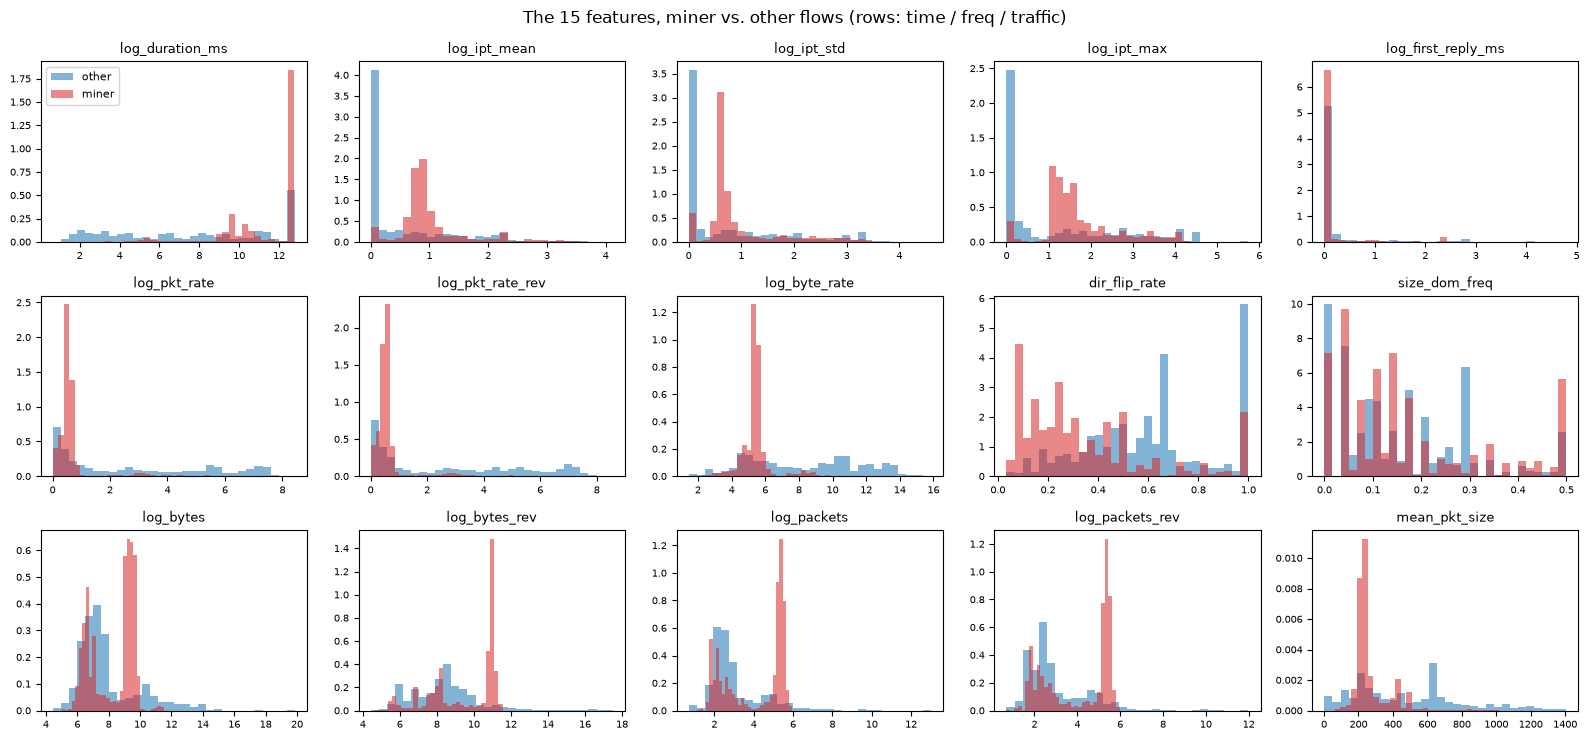

In [6]:
FEATURES = {
    "time":    ["log_duration_ms", "log_ipt_mean", "log_ipt_std", "log_ipt_max", "log_first_reply_ms"],
    "freq":    ["log_pkt_rate", "log_pkt_rate_rev", "log_byte_rate", "dir_flip_rate", "size_dom_freq"],
    "traffic": ["log_bytes", "log_bytes_rev", "log_packets", "log_packets_rev", "mean_pkt_size"],
}
FEATURE_NAMES = [f for g in GROUPS for f in FEATURES[g]]

def flow_features(df):
    """15 features per flow, computed from the flow summary and the first-30-packet arrays (CHOICE: see the table above)."""
    dur_ms = (pd.to_datetime(df.TIME_LAST) - pd.to_datetime(df.TIME_FIRST)).dt.total_seconds().to_numpy() * 1e3
    dur_ms = np.maximum(dur_ms, 0.0); dur_s = np.maximum(dur_ms, 1.0) / 1e3
    rows = []
    for i, (dirs, lens, times) in enumerate(zip(df.DIRS.to_numpy(), df.LENS.to_numpy(), df.TIMES.to_numpy())):
        d = np.array(dirs.strip("[]").split("|"), dtype=float)
        l = np.array(lens.strip("[]").split("|"), dtype=float)
        t = pd.to_datetime(pd.Series(times.strip("[]").split("|"))).astype("int64").to_numpy() / 1e6     # milliseconds
        ipt = np.diff(t) if len(t) > 1 else np.zeros(1)
        server = np.where(d < 0)[0]
        reply = (t[server[0]] - t[0]) if len(server) else 0.0
        flips = float(np.mean(d[1:] != d[:-1])) if len(d) > 1 else 0.0
        dom = (np.argmax(np.abs(np.fft.rfft(l - l.mean()))[1:]) + 1) / len(l) if len(l) >= 4 else 0.0
        rows.append([ipt.mean(), ipt.std(), ipt.max(), reply, flips, dom, l.mean()])
    a = np.array(rows)
    out = np.column_stack([
        np.log1p(dur_ms), np.log1p(a[:, 0]), np.log1p(a[:, 1]), np.log1p(a[:, 2]), np.log1p(np.maximum(a[:, 3], 0)),
        np.log1p(df.PACKETS / dur_s), np.log1p(df.PACKETS_REV / dur_s), np.log1p((df.BYTES + df.BYTES_REV) / dur_s), a[:, 4], a[:, 5],
        np.log1p(df.BYTES), np.log1p(df.BYTES_REV), np.log1p(df.PACKETS), np.log1p(df.PACKETS_REV), a[:, 6]])
    return pd.DataFrame(out, columns=FEATURE_NAMES)

t0 = time.time()
feat_design = flow_features(raw_design); y_design = (raw_design.LABEL == "Miner").astype(int).to_numpy()
feat_eval   = flow_features(raw_eval);   y_eval   = (raw_eval.LABEL == "Miner").astype(int).to_numpy()
print(f"features for {len(feat_design)+len(feat_eval):,} flows in {time.time()-t0:.0f} s | label: 1 = miner (positive class), 0 = other")
display(feat_design.groupby(y_design).mean().rename(index={0: "other", 1: "miner"}).T.round(2))

fig, axes = plt.subplots(3, 5, figsize=(16, 7.5))
for ax, name in zip(axes.ravel(), FEATURE_NAMES):
    for lab, col, txt in ((0, "tab:blue", "other"), (1, "tab:red", "miner")):
        ax.hist(feat_design.loc[y_design == lab, name], bins=30, alpha=0.55, color=col, label=txt, density=True)
    ax.set_title(name, fontsize=9); ax.tick_params(labelsize=7)
axes[0, 0].legend(fontsize=8); fig.suptitle("The 15 features, miner vs. other flows (rows: time / freq / traffic)")
plt.tight_layout(); plt.show()

## 3. Splits and preprocessing (nothing is fitted on test data)

The paper uses 70 % of the data for training and 30 % for testing. We add one more split *inside* the training part, because
the method has two things to choose after the quantum circuits are trained, the QAOA weights and the threshold `T`, and those
must not be chosen on the test data (the paper does not say where it chose them):

| Part | Share | Used for |
|---|---|---|
| **sub-train** | 56 % | training the three QNN layers; fitting the clipping/scaling |
| **validation** | 14 % | QAOA weights, threshold `T` of Eq. 16 |
| **test** | 30 % | all reported metrics |
| **later test** (March 2022 file) | extra | drift check, never touched before the end |

The scaler clips every feature to the 1st-99th percentile of sub-train and maps it linearly to `[0, pi]`, so that a feature
value is directly a rotation angle (a long tail would otherwise squash everything else into a sliver of the circle).
Classical baselines get the identical scaled 15-column matrix and are trained on sub-train + validation.

In [7]:
def make_split(seed):
    idx = np.arange(len(y_design))
    train, test = train_test_split(idx, test_size=TEST_SIZE, stratify=y_design, random_state=seed)
    sub, val = train_test_split(train, test_size=VAL_FRACTION, stratify=y_design[train], random_state=seed)
    return sub, val, test

class AngleScaler:
    """Clip to the training 1st/99th percentile, then min-max to [0, pi]. Fitted on the sub-train part only."""
    def fit(self, X):
        self.lo, self.hi = np.percentile(X, 1, axis=0), np.percentile(X, 99, axis=0)
        self.mm = MinMaxScaler((0, np.pi)).fit(np.clip(X, self.lo, self.hi)); return self
    def transform(self, X):
        return np.clip(self.mm.transform(np.clip(X, self.lo, self.hi)), 0, np.pi)

def prepare(seed):
    sub, val, test = make_split(seed)
    Xall = feat_design.to_numpy()
    sc = AngleScaler().fit(Xall[sub])
    d = dict(seed=seed, scaler=sc, idx=dict(sub=sub, val=val, test=test),
             X=dict(sub=sc.transform(Xall[sub]), val=sc.transform(Xall[val]), test=sc.transform(Xall[test]),
                    late=sc.transform(feat_eval.to_numpy())),
             y=dict(sub=y_design[sub], val=y_design[val], test=y_design[test], late=y_eval))
    return d

data0 = prepare(SEED)
print({k: (v.shape, int(data0["y"][k].sum()), "miners") for k, v in data0["X"].items()})
print("value range after scaling (sub-train):", data0["X"]["sub"].min().round(3), "to", data0["X"]["sub"].max().round(3), "(should be 0 to pi = 3.142)")

{'sub': ((3360, 15), 1680, 'miners'), 'val': ((840, 15), 420, 'miners'), 'test': ((1800, 15), 900, 'miners'), 'late': ((4000, 15), 2000, 'miners')}
value range after scaling (sub-train): 0.0 to 3.142 (should be 0 to pi = 3.142)


## 4. Classical baselines on exactly the same inputs

The paper compares with two other *quantum* methods on its own private data and never trains a classical model. Before building
anything quantum we ask the obvious question: what does a plain classical classifier reach on the same 15 scaled columns? Three
models (random forest, RBF support-vector machine, logistic regression) are trained on sub-train + validation and scored on the
test part and on the later March sample. The random forest is also fitted on each *feature group alone*, which says how much
information each of the three QNN layers can possibly use.

The metric set is the paper's Table II. With miner as the positive class:

* accuracy, precision, recall, F1 as usual; **specificity** = TN/(TN+FP); **FER** (false error rate) = FP/(FP+TN) = 1 - specificity;
  **FDR** (false discovery rate) = FP/(FP+TP) = 1 - precision;
* **MAPE** is undefined for a classifier; we code benign = 1 and miner = 2 and take `mean(|y - y_hat| / y)`.

In [8]:
def cls_metrics(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    return dict(F1=2 * prec * rec / max(prec + rec, 1e-12), Recall=rec, Accuracy=(tp + tn) / len(y),
                FER=fp / max(fp + tn, 1), MAPE=float(np.mean(np.abs((y + 1) - (pred + 1)) / (y + 1))),
                Specificity=tn / max(tn + fp, 1), FDR=fp / max(fp + tp, 1), Precision=prec)

def baseline_models(seed):
    return {"RandomForest":       RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1),
            "SVC (rbf)":          SVC(kernel="rbf", C=1.0, random_state=seed),
            "LogisticRegression": LogisticRegression(max_iter=2000, random_state=seed)}

def run_baselines(d):
    Xtr = np.vstack([d["X"]["sub"], d["X"]["val"]]); ytr = np.concatenate([d["y"]["sub"], d["y"]["val"]])
    rows = []
    for name, m in baseline_models(d["seed"]).items():
        t0 = time.perf_counter(); m.fit(Xtr, ytr); fit_s = time.perf_counter() - t0
        for split in ("test", "late"):
            rows.append(dict(model=name, split=split, fit_s=fit_s, **cls_metrics(d["y"][split], m.predict(d["X"][split]))))
    for gi, g in enumerate(GROUPS):                       # information content of each QNN layer's input
        cols = slice(gi * FEATS_PER_GROUP, (gi + 1) * FEATS_PER_GROUP)
        m = RandomForestClassifier(n_estimators=200, random_state=d["seed"], n_jobs=-1).fit(Xtr[:, cols], ytr)
        for split in ("test", "late"):
            rows.append(dict(model=f"RandomForest on '{g}' features only", split=split, fit_s=np.nan,
                             **cls_metrics(d["y"][split], m.predict(d["X"][split][:, cols]))))
    return pd.DataFrame(rows)

base0 = run_baselines(data0)
display(base0[base0.split == "test"].set_index("model")[["Accuracy", "F1", "Recall", "Precision", "Specificity", "FER", "FDR", "MAPE", "fit_s"]].round(3))
print("later test set (March 2022):")
display(base0[base0.split == "late"].set_index("model")[["Accuracy", "F1", "Recall", "Specificity", "FER", "FDR"]].round(3))

,Accuracy,F1,Recall,Precision,Specificity,FER,FDR,MAPE,fit_s
model,,,,,,,,,
RandomForest,0.986,0.986,0.981,0.991,0.991,0.009,0.009,0.009,0.904
SVC (rbf),0.954,0.953,0.928,0.980,0.981,0.019,0.020,0.028,0.546
LogisticRegression,0.913,0.912,0.893,0.931,0.933,0.067,0.069,0.060,0.202
RandomForest on 'time' features only,0.957,0.956,0.951,0.962,0.962,0.038,0.038,0.031,NaN
RandomForest on 'freq' features only,0.947,0.946,0.939,0.954,0.954,0.046,0.046,0.038,NaN
RandomForest on 'traffic' features only,0.978,0.978,0.968,0.988,0.988,0.012,0.012,0.014,NaN


later test set (March 2022):


,Accuracy,F1,Recall,Specificity,FER,FDR
model,,,,,,
RandomForest,0.848,0.822,0.702,0.993,0.007,0.010
SVC (rbf),0.842,0.824,0.740,0.943,0.057,0.072
LogisticRegression,0.906,0.906,0.908,0.904,0.096,0.096
RandomForest on 'time' features only,0.830,0.806,0.710,0.950,0.050,0.066
RandomForest on 'freq' features only,0.707,0.617,0.472,0.942,0.058,0.110
RandomForest on 'traffic' features only,0.930,0.926,0.880,0.980,0.020,0.022


## 5. The quantum layer: three small variational circuits

Each of the three QNN layers is the same kind of circuit on its own set of qubits (6, 7, 7 as in Table I):

1. **Encoding.** Feature `x_i` (an angle in `[0, pi]`) is written on qubit `i` with a rotation `RY(x_i)`; five features
   occupy five qubits. The remaining 1 (time layer) or 2 (freq and traffic layers) qubits start in `|0>` and act as trainable
   "hidden" qubits: they take part in the entangling gates but carry no data. *CHOICE: the paper allocates 20 qubits to 15
   features without saying how.*
2. **Trainable part.** Three layers of `StronglyEntanglingLayers`: every qubit gets a general rotation `Rot(phi, theta, omega)`
   (three trainable angles) and then a ring of CNOT gates connects the qubits. For the 6-qubit layer that is 54 trainable
   angles, for the 7-qubit layers 63. *CHOICE:* the data are **re-uploaded**: the same `RY(x_i)` rotations are applied again
   before the second and third layer (`REUPLOAD = True`). Without it each feature enters the circuit only once and the
   circuit is a low-degree trigonometric polynomial of the inputs; in a short test it stayed near 0.80 accuracy per layer,
   about 5 points below a plain logistic regression on the same five columns, and re-uploading brought it to 0.83-0.85. The
   paper's "quantum gates as activation function" leaves this open; setting `REUPLOAD = False` gives the plain version.
3. **Read-out.** The expectation value `F = <Z>` of qubit 0, a number in `[-1, +1]`. Training pushes it towards `+1` for
   miner flows and `-1` for others, with the mean-squared error as loss.

A statevector simulation of such a circuit on a batch of 32 flows takes milliseconds when written directly as tensor
operations, whereas PennyLane's generic QNode machinery was about 5 times slower for the same job in our test (about 200 ms against
30-50 ms per gradient step) and the paper's 50 epochs mean thousands of gradient steps. We therefore write the simulator ourselves (about 25 lines of numpy that
`autograd` can differentiate), and **check it against PennyLane's own circuit** to make sure that it is the same circuit.

time    : 6 qubits, 54 trainable angles, matches PennyLane (RY embedding + StronglyEntanglingLayers): True
freq    : 7 qubits, 63 trainable angles, matches PennyLane (RY embedding + StronglyEntanglingLayers): True
traffic : 7 qubits, 63 trainable angles, matches PennyLane (RY embedding + StronglyEntanglingLayers): True

The time layer as a PennyLane circuit (data x_0..x_4 on qubits 0-4, qubit 5 is the hidden qubit):


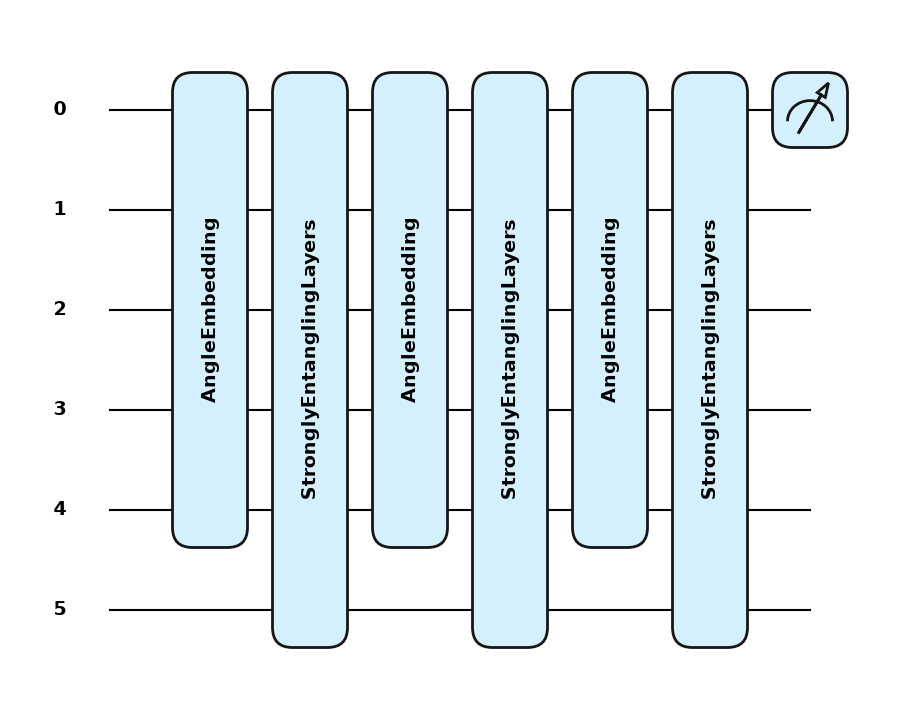

In [9]:
def cnot_perm(n, c, t):
    idx = np.arange(2 ** n)
    return np.where(((idx >> (n - 1 - c)) & 1) == 1, idx ^ (1 << (n - 1 - t)), idx)

class SubQNN:
    """Statevector simulation of  AngleEmbedding(RY) + StronglyEntanglingLayers + <Z_0>  on n qubits (wire 0 = most significant bit)."""
    def __init__(self, n_qubits, n_feat, layers):
        self.n, self.nf, self.L = n_qubits, n_feat, layers
        self.perms = []
        for l in range(layers):                                  # StronglyEntanglingLayers: CNOT(i, (i + r) mod n), r = l mod (n-1) + 1
            r, cur = l % (n_qubits - 1) + 1, np.arange(2 ** n_qubits)
            for i in range(n_qubits):
                cur = cur[cnot_perm(n_qubits, i, (i + r) % n_qubits)]
            self.perms.append(cur)
        self.z0 = 1.0 - 2.0 * ((np.arange(2 ** n_qubits) >> (n_qubits - 1)) & 1)
    @property
    def n_params(self): return self.L * self.n * 3
    def init_weights(self, r):
        return r.normal(0.0, INIT_STD, (self.L, self.n, 3))               # CHOICE: small random start (see configuration cell)
    def encode(self, X):
        """Data part of the circuit. It has no trainable parameters, so it is computed once per flow:
        the product state RY(x_i)|0> (first upload) and the RY(x_i) matrices that are re-applied before layers 2 and 3."""
        B = len(X); psi = np.ones((B, 1), dtype=complex)
        for q in range(self.n):
            v = np.stack([np.cos(X[:, q] / 2), np.sin(X[:, q] / 2)], 1) if q < self.nf else np.stack([np.ones(B), np.zeros(B)], 1)
            psi = (psi[:, :, None] * v[:, None, :]).reshape(B, -1)
        c, s = np.cos(X / 2), np.sin(X / 2)
        G = np.stack([np.stack([c, -s], -1), np.stack([s, c], -1)], -2).astype(complex) if REUPLOAD else None   # (B, nf, 2, 2)
        return psi, G
    @staticmethod
    def take(enc, idx):
        return enc[0][idx], (None if enc[1] is None else enc[1][idx])
    def forward(self, w, enc):
        psi, G = enc; B = psi.shape[0]
        for l in range(self.L):
            if REUPLOAD and l > 0:                                       # data re-uploading: the same RY(x_i) again before every further layer
                for q in range(self.nf):
                    psi = anp.einsum('pab,pqbr->pqar', G[:, q], psi.reshape(B, 2 ** q, 2, -1)).reshape(B, -1)
            phi, th, om = w[l, :, 0], w[l, :, 1], w[l, :, 2]            # Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)
            c, s = anp.cos(th / 2), anp.sin(th / 2)
            a, b = anp.exp(-0.5j * (phi + om)), anp.exp(-0.5j * (phi - om))
            M = anp.stack([anp.stack([a * c, -anp.conj(b) * s], axis=1), anp.stack([b * s, anp.conj(a) * c], axis=1)], axis=1)
            for q in range(self.n):
                psi = anp.einsum('ab,pqbr->pqar', M[q], psi.reshape(B, 2 ** q, 2, -1)).reshape(B, -1)
            psi = psi[:, self.perms[l]]                                  # the CNOT ring is a permutation of the basis states
        return anp.sum(anp.real(psi * anp.conj(psi)) * self.z0, axis=1)  # <Z_0>
    def predict(self, w, X):
        return np.concatenate([np.asarray(self.forward(w, self.encode(X[i:i + 1024]))) for i in range(0, len(X), 1024)])

NETS = {g: SubQNN(QUBITS[g], FEATS_PER_GROUP, N_LAYERS) for g in GROUPS}

def pennylane_reference(net):
    """The same circuit written with PennyLane's own gates: [RY(x) embedding, StronglyEntanglingLayers layer] x L."""
    dev = qml.device("default.qubit", wires=net.n)
    @qml.qnode(dev)
    def circuit(x, w):
        for l in range(net.L):
            if l == 0 or REUPLOAD:
                qml.AngleEmbedding(x, wires=range(net.nf), rotation="Y")
            qml.StronglyEntanglingLayers(w[l:l + 1], wires=range(net.n), ranges=[l % (net.n - 1) + 1])
        return qml.expval(qml.PauliZ(0))
    return circuit

# ---- check against PennyLane's own circuit ----
for g in GROUPS:
    net = NETS[g]; reference = pennylane_reference(net)
    w_test = np.random.default_rng(1).uniform(0, 2 * np.pi, (net.L, net.n, 3)); x_test = np.random.default_rng(2).uniform(0, np.pi, (16, net.nf))
    ok = np.allclose(net.predict(w_test, x_test), np.asarray(reference(x_test, w_test)), atol=1e-10)
    print(f"{g:8s}: {net.n} qubits, {net.n_params} trainable angles, matches PennyLane (RY embedding + StronglyEntanglingLayers): {ok}")
    assert ok

net = NETS["time"]
print("\nThe time layer as a PennyLane circuit (data x_0..x_4 on qubits 0-4, qubit 5 is the hidden qubit):")
fig, _ = qml.draw_mpl(pennylane_reference(net), decimals=1, style="pennylane")(np.zeros(net.nf), np.zeros((N_LAYERS, net.n, 3)))
plt.show()

## 6. Training the three QNN layers

Each layer is trained separately on **its own five features** with mini-batches of 32 flows, learning rate 0.01 and the paper's
50 epochs (12 in `FAST_MODE`). The gradient is exact (back-propagation through the simulation) rather than estimated from
shots or parameter shifts, which is what "quantum gradient descent" amounts to on a noiseless simulator.

All weights start as small random angles (normal, standard deviation `INIT_STD = 0.1`, `CHOICE`): with angles drawn uniformly
from `[0, 2 pi]` the circuits trained noticeably worse in a short test.

`OPTIMIZER = "gd"` is plain gradient descent exactly as the paper's table says. In a short test it started more slowly than Adam
at the same learning rate 0.01 (validation accuracy 0.73 against 0.79 after 5 epochs) and ended 1-2 points lower after 20 epochs, so the
default here is **Adam with the same learning rate 0.01** (`CHOICE`); set `OPTIMIZER = "gd"` to see the difference.

The validation accuracy (sign of `F`) is recorded after every epoch to draw the learning curves. It is never used to stop
training early.

training with 'adam', lr 0.01, batch 32, 50 epochs on 3360 flows per layer


  time     (6 qubits): 50 epochs, 215 s, final loss 0.479, validation accuracy 0.826


  freq     (7 qubits): 50 epochs, 311 s, final loss 0.552, validation accuracy 0.813


  traffic  (7 qubits): 50 epochs, 329 s, final loss 0.510, validation accuracy 0.835


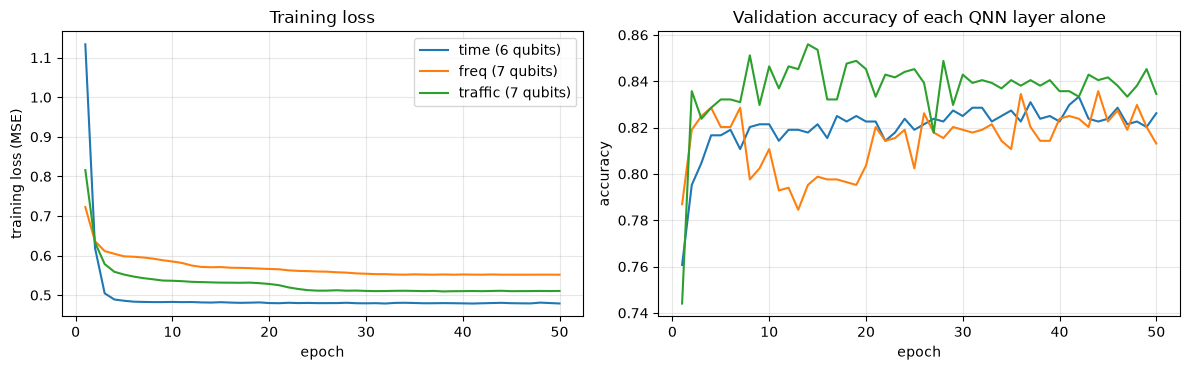

time     layer alone, test accuracy 0.834
freq     layer alone, test accuracy 0.819
traffic  layer alone, test accuracy 0.851


In [10]:
def train_subqnn(g, d, seed, epochs=EPOCHS, verbose=True):
    net = NETS[g]; gi = GROUPS.index(g); cols = slice(gi * FEATS_PER_GROUP, (gi + 1) * FEATS_PER_GROUP)
    r = np.random.default_rng(seed * 1000 + gi)
    w = net.init_weights(r)
    psi_sub = net.encode(d["X"]["sub"][:, cols]); Y = 2.0 * d["y"]["sub"] - 1.0
    gradient = value_and_grad(lambda w_, p_, y_: anp.mean((net.forward(w_, p_) - y_) ** 2))
    m, v, t = np.zeros_like(w), np.zeros_like(w), 0
    hist = dict(loss=[], val_acc=[]); t0 = time.perf_counter()
    for ep in range(epochs):
        perm = r.permutation(len(Y)); losses = []
        for i in range(0, len(perm), BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            loss, gw = gradient(w, net.take(psi_sub, idx), Y[idx]); losses.append(float(loss))
            if OPTIMIZER == "gd":
                w = w - LEARNING_RATE * gw
            else:                                                       # Adam, same learning rate
                t += 1; m = 0.9 * m + 0.1 * gw; v = 0.999 * v + 0.001 * gw ** 2
                w = w - LEARNING_RATE * (m / (1 - 0.9 ** t)) / (np.sqrt(v / (1 - 0.999 ** t)) + 1e-8)
        hist["loss"].append(float(np.mean(losses)))
        hist["val_acc"].append(float(np.mean((net.predict(w, d["X"]["val"][:, cols]) > 0) == d["y"]["val"])))
    secs = time.perf_counter() - t0
    if verbose: print(f"  {g:8s} ({net.n} qubits): {epochs} epochs, {secs:.0f} s, final loss {hist['loss'][-1]:.3f}, validation accuracy {hist['val_acc'][-1]:.3f}")
    return dict(w=w, hist=hist, secs=secs, cols=cols)

def qnn_outputs(models, d):
    """F_time, F_freq, F_traffic for every split -> arrays of shape (n, 3)."""
    return {s: np.column_stack([NETS[g].predict(models[g]["w"], d["X"][s][:, models[g]["cols"]]) for g in GROUPS]) for s in ("sub", "val", "test", "late")}

print(f"training with {OPTIMIZER!r}, lr {LEARNING_RATE}, batch {BATCH_SIZE}, {EPOCHS} epochs on {len(data0['y']['sub'])} flows per layer")
models0 = {g: train_subqnn(g, data0, SEED) for g in GROUPS}
F0 = qnn_outputs(models0, data0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for g in GROUPS:
    axes[0].plot(range(1, EPOCHS + 1), models0[g]["hist"]["loss"], label=f"{g} ({NETS[g].n} qubits)")
    axes[1].plot(range(1, EPOCHS + 1), models0[g]["hist"]["val_acc"], label=g)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training loss (MSE)"); axes[0].set_title("Training loss"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Validation accuracy of each QNN layer alone"); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
for g, k in zip(GROUPS, range(3)):
    print(f"{g:8s} layer alone, test accuracy {np.mean((F0['test'][:, k] > 0) == data0['y']['test']):.3f}")

## 7. Algorithm 1: QAOA for the weights `w_time, w_freq, w_traffic`

The three layers give three numbers per flow. The paper combines them as `O = w_time F_time + w_freq F_freq + w_traffic F_traffic`
(Eq. 11 and 13) and finds the weights with the Quantum Approximate Optimization Algorithm. QAOA solves problems over bit strings,
so the weights have to be bit strings first. Our reading (`CHOICE`; the paper does not give the cost Hamiltonian):

* each weight is a 3-bit number, `w = k / 7` with `k = 0..7`; three weights = **9 qubits**, 512 candidate weight triples;
* the **cost** of a bit string is the quantity the paper wants to minimise in Eq. 16: build `O` with those weights on the
  validation flows, choose the best threshold `T`, and take the resulting `lambda * FPR + (1 - lambda) * FNR`. This is a diagonal
  "cost Hamiltonian" `C` with 512 entries;
* QAOA of depth `p`: start in the uniform superposition `H^n |0>` (Algorithm 1, line 2), then `p` times apply the cost phase
  `exp(-i gamma_k C)` and the mixer `prod_j RX_j(2 beta_k)`; **measure**, and let a classical optimiser update `gamma, beta`
  (kept inside `[0, pi]` as in Table I) to minimise the expected cost for 100 iterations;
* finally the weights are read from the **most frequently measured bit string** (line 10, `ExtractWeights`).

Because only 512 triples exist, the cost table can be evaluated for all of them. That lets us do two things the paper does not:
check QAOA against the true optimum (brute force) and against equal weights.

QAOA simulator on 9 qubits matches PennyLane (DiagonalQubitUnitary + RX).


cost table over 512 weight triples and 3 QAOA restarts x 100 iterations: 4 s
validation cost of Eq. 16 (lambda=0.5):  equal weights 0.1119 | brute-force best 0.1048 [0.14 0.57 1.  ] | QAOA bit string 0.1060 [0.14 0.43 1.  ] (only 1 of 512 triples are better) | worst 0.5000
QAOA: expected cost after training 0.1143 (a uniformly random weight triple has 0.1246); probability of the brute-force optimum 0.007 (uniform guess: 0.0020); gamma=[1.2  3.14], beta=[2.83 2.9 ]


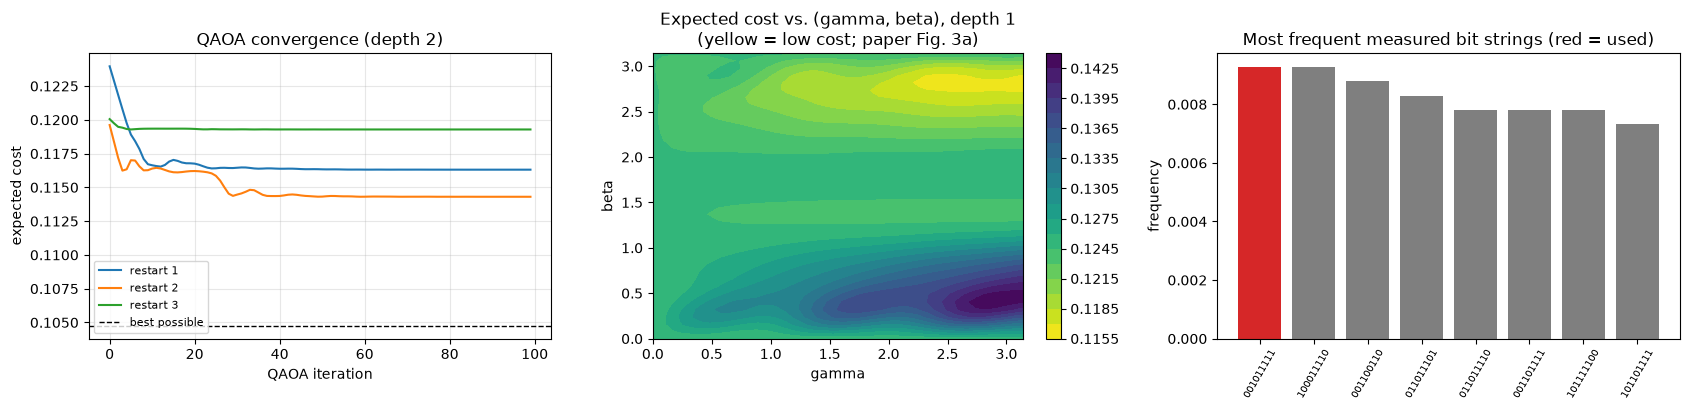

In [11]:
N_QAOA = 3 * BITS_PER_WEIGHT; N_STATES = 2 ** N_QAOA; LEVELS = 2 ** BITS_PER_WEIGHT - 1

def bitstring_weights(i):
    """Integer 0..511 -> (w_time, w_freq, w_traffic) in {0, 1/7, ..., 1}; w_time is the most significant block of bits."""
    mask = LEVELS
    return np.array([(i >> (BITS_PER_WEIGHT * (2 - k))) & mask for k in range(3)]) / LEVELS
W_ALL = np.array([bitstring_weights(i) for i in range(N_STATES)])

def best_threshold(score, y, lam=LAMBDA):
    """Eq. 16:  T = argmin  lam * P(QM_benign >= T) + (1 - lam) * P(QM_malicious < T);  returns (T, minimal cost). Exact search."""
    order = np.argsort(score, kind="stable"); s, yo = score[order], y[order]; n = len(y)
    n_mal, n_ben = max(int(y.sum()), 1), max(int(n - y.sum()), 1)
    fnr = np.concatenate([[0], np.cumsum(yo)]) / n_mal                     # malicious flows below T (called genuine)
    fpr = (n_ben - np.concatenate([[0], np.cumsum(1 - yo)])) / n_ben        # benign flows at or above T (called malicious)
    J = lam * fpr + (1 - lam) * fnr
    J[1:-1] = np.where(s[1:] > s[:-1], J[1:-1], np.inf)                    # no threshold inside a run of equal scores
    k = int(np.argmin(J))
    T = s[0] - 1e-9 if k == 0 else (s[-1] + 1e-9 if k == n else 0.5 * (s[k - 1] + s[k]))
    return float(T), float(J[k])

def phase_of(cost):
    """Cost table -> phase angles: min-max scaled to [0, QAOA_COST_SCALE] (CHOICE) so that gamma in [0, pi] can turn the phases by several radians."""
    return QAOA_COST_SCALE * (cost - cost.min()) / (cost.max() - cost.min())

def cost_table(F_val, y_val):
    return np.array([best_threshold(F_val @ w, y_val)[1] for w in W_ALL])

def qaoa_probs(gam, bet, cn):
    """|+>^n -> p x [ exp(-i gamma C) , prod_j RX_j(2 beta) ] -> probabilities of the 2^n bit strings (cn = normalised cost, diagonal of C)."""
    psi = anp.ones(N_STATES, dtype=complex) / np.sqrt(N_STATES)
    for g_, b_ in zip(gam, bet):
        psi = psi * anp.exp(-1j * g_ * cn)
        RX = anp.array([[anp.cos(b_), -1j * anp.sin(b_)], [-1j * anp.sin(b_), anp.cos(b_)]])
        for q in range(N_QAOA):
            psi = anp.einsum('ab,pbr->par', RX, psi.reshape(2 ** q, 2, -1)).reshape(-1)
    return anp.real(psi * anp.conj(psi))

# check against PennyLane (the same circuit written with qml gates)
_cn = np.random.default_rng(0).random(N_STATES); _g, _b = np.array([0.7, 1.9]), np.array([0.4, 2.2])
_dev = qml.device("default.qubit", wires=N_QAOA)
@qml.qnode(_dev)
def _qaoa_ref(gam, bet):
    for q in range(N_QAOA): qml.Hadamard(q)
    for g_, b_ in zip(gam, bet):
        qml.DiagonalQubitUnitary(np.exp(-1j * g_ * _cn), wires=range(N_QAOA))
        for q in range(N_QAOA): qml.RX(2 * b_, wires=q)
    return qml.probs(wires=range(N_QAOA))
assert np.allclose(qaoa_probs(_g, _b, _cn), _qaoa_ref(_g, _b)); print(f"QAOA simulator on {N_QAOA} qubits matches PennyLane (DiagonalQubitUnitary + RX).")

def optimise_qaoa(cn, seed, p=QAOA_LAYERS, iters=QAOA_ITERS, restarts=QAOA_RESTARTS):
    r = np.random.default_rng(seed)
    value_grad = value_and_grad(lambda th: anp.sum(qaoa_probs(th[:p], th[p:], cn) * cn) / QAOA_COST_SCALE)
    runs = []
    for _ in range(restarts):
        th = r.uniform(0, np.pi, 2 * p); m, v = np.zeros_like(th), np.zeros_like(th); hist = []
        for it in range(1, iters + 1):
            val, gr = value_grad(th); hist.append(float(val))
            m = 0.9 * m + 0.1 * gr; v = 0.999 * v + 0.001 * gr ** 2
            th = np.clip(th - QAOA_LR * (m / (1 - 0.9 ** it)) / (np.sqrt(v / (1 - 0.999 ** it)) + 1e-8), 0, np.pi)   # gamma, beta in [0, pi]
        runs.append(dict(theta=th, hist=hist, final=float(anp.sum(qaoa_probs(th[:p], th[p:], cn) * cn) / QAOA_COST_SCALE)))
    best = min(runs, key=lambda x: x["final"])
    probs = np.asarray(qaoa_probs(best["theta"][:p], best["theta"][p:], cn))
    shots = r.choice(N_STATES, size=QAOA_SHOTS, p=probs / probs.sum())          # "Measure(psi)"
    counts = np.bincount(shots, minlength=N_STATES)
    return dict(runs=runs, best=best, probs=probs, counts=counts, chosen=int(np.argmax(counts)))

t0 = time.perf_counter()
cost0 = cost_table(F0["val"], data0["y"]["val"])
cmin, cmax = cost0.min(), cost0.max(); cn0 = phase_of(cost0)
q0 = optimise_qaoa(cn0, SEED)
print(f"cost table over {N_STATES} weight triples and {QAOA_RESTARTS} QAOA restarts x {QAOA_ITERS} iterations: {time.perf_counter()-t0:.0f} s")

w_equal = np.ones(3); w_brute = W_ALL[int(np.argmin(cost0))]; w_qaoa = W_ALL[q0["chosen"]]
rank = int((cost0 < cost0[q0["chosen"]]).sum())
print(f"validation cost of Eq. 16 (lambda={LAMBDA}):  equal weights {cost0[np.argmax(W_ALL.sum(1))]:.4f} | brute-force best {cost0.min():.4f} {np.round(w_brute, 2)} | "
      f"QAOA bit string {cost0[q0['chosen']]:.4f} {np.round(w_qaoa, 2)} (only {rank} of {N_STATES} triples are better) | worst {cost0.max():.4f}")
print(f"QAOA: expected cost after training {cmin + (cmax-cmin)*q0['best']['final']:.4f} (a uniformly random weight triple has {cost0.mean():.4f}); probability of the brute-force optimum "
      f"{q0['probs'][int(np.argmin(cost0))]:.3f} (uniform guess: {1/N_STATES:.4f}); gamma={np.round(q0['best']['theta'][:QAOA_LAYERS],2)}, beta={np.round(q0['best']['theta'][QAOA_LAYERS:],2)}")

# --- Fig. 3a analogue: expected cost as a function of gamma, beta for depth 1 ---
gs = np.linspace(0, np.pi, 40); land = np.array([[float(anp.sum(qaoa_probs([g_], [b_], cn0) * cn0)) / QAOA_COST_SCALE for g_ in gs] for b_ in gs])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for k, h in enumerate(q0["runs"]):
    axes[0].plot(np.array(h["hist"]) * (cmax - cmin) + cmin, label=f"restart {k+1}")
axes[0].axhline(cmin, color="k", ls="--", lw=1, label="best possible"); axes[0].set_xlabel("QAOA iteration"); axes[0].set_ylabel("expected cost")
axes[0].set_title(f"QAOA convergence (depth {QAOA_LAYERS})"); axes[0].legend(fontsize=8); axes[0].grid(alpha=.3)
im = axes[1].contourf(gs, gs, land * (cmax - cmin) + cmin, 25, cmap="viridis_r"); axes[1].set_xlabel("gamma"); axes[1].set_ylabel("beta")
axes[1].set_title("Expected cost vs. (gamma, beta), depth 1\n(yellow = low cost; paper Fig. 3a)"); fig.colorbar(im, ax=axes[1])
top = np.argsort(q0["counts"])[::-1][:8]
axes[2].bar(range(8), q0["counts"][top] / QAOA_SHOTS, color=["tab:red" if t == q0["chosen"] else "tab:gray" for t in top])
axes[2].set_xticks(range(8)); axes[2].set_xticklabels([f"{t:0{N_QAOA}b}" for t in top], rotation=60, fontsize=7)
axes[2].set_title("Most frequent measured bit strings (red = used)"); axes[2].set_ylabel("frequency")
plt.tight_layout(); plt.show()

## 8. Algorithm 2: the QML filtration layer

For every flow the quantum metric is the weighted sum `QM = w_time F_time + w_freq F_freq + w_traffic F_traffic`. A flow with
`QM >= T` is flagged **malicious** (dropped), otherwise **genuine**. The threshold `T` is the one that minimises Eq. 16 on the
validation flows. The cell below runs this for the QAOA weights and, as references, for

* **equal weights** (no optimisation at all),
* the **brute-force best** weights out of the 512 candidates (what a perfect QAOA would return),
* each **QNN layer on its own** (weight 1 on one layer, 0 on the others),
* **Eq. 15** as printed (`QM = w_freq F_freq + w_traffic F_traffic`, the time layer left out).

TEST split (30 % of the design sample):


,T,w_time,w_freq,w_traffic,Accuracy,F1,Recall,Specificity,FER,FDR,MAPE
variant,,,,,,,,,,,
Quant-Jack (QAOA weights),-0.030,0.143,0.429,1.0,0.888,0.884,0.854,0.922,0.078,0.083,0.075
equal weights,0.016,1.000,1.000,1.0,0.891,0.887,0.857,0.924,0.076,0.081,0.074
brute-force best weights,-0.043,0.143,0.571,1.0,0.882,0.879,0.856,0.909,0.091,0.096,0.082
Eq. 15 (freq + traffic only),-0.054,0.000,0.429,1.0,0.878,0.878,0.878,0.879,0.121,0.121,0.091
time layer alone,-0.011,1.000,0.000,0.0,0.838,0.837,0.828,0.849,0.151,0.154,0.119
freq layer alone,-0.042,0.000,1.000,0.0,0.837,0.848,0.913,0.760,0.240,0.208,0.142
traffic layer alone,0.138,0.000,0.000,1.0,0.867,0.852,0.762,0.972,0.028,0.035,0.073


LATER test set (March 2022 flows, never used for any choice):


,T,w_time,w_freq,w_traffic,Accuracy,F1,Recall,Specificity,FER,FDR,MAPE
variant,,,,,,,,,,,
Quant-Jack (QAOA weights),-0.030,0.143,0.429,1.0,0.867,0.860,0.819,0.915,0.085,0.094,0.088
equal weights,0.016,1.000,1.000,1.0,0.891,0.885,0.842,0.940,0.060,0.067,0.070
brute-force best weights,-0.043,0.143,0.571,1.0,0.882,0.879,0.855,0.910,0.090,0.095,0.081
Eq. 15 (freq + traffic only),-0.054,0.000,0.429,1.0,0.866,0.868,0.882,0.848,0.152,0.147,0.105
time layer alone,-0.011,1.000,0.000,0.0,0.708,0.665,0.580,0.836,0.164,0.221,0.187
freq layer alone,-0.042,0.000,1.000,0.0,0.834,0.839,0.868,0.799,0.201,0.188,0.133
traffic layer alone,0.138,0.000,0.000,1.0,0.847,0.833,0.764,0.930,0.070,0.084,0.094


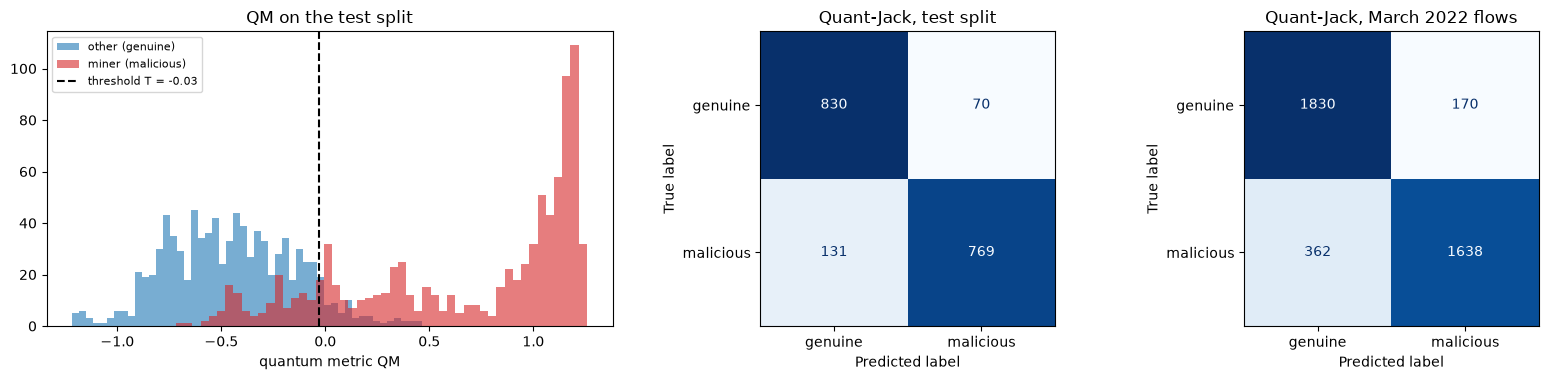

In [12]:
def filtration(F, w, T):
    """Algorithm 2: QM = F @ w; QM >= T -> 'Malicious' (1), else 'Genuine' (0)."""
    return (F @ w >= T).astype(int)

def run_filters(d, F, w_qaoa, w_brute):
    variants = {"Quant-Jack (QAOA weights)": w_qaoa, "equal weights": np.ones(3), "brute-force best weights": w_brute,
                "Eq. 15 (freq + traffic only)": np.array([0.0, w_qaoa[1], w_qaoa[2]]),
                "time layer alone": np.array([1.0, 0, 0]), "freq layer alone": np.array([0, 1.0, 0]), "traffic layer alone": np.array([0, 0, 1.0])}
    rows, store = [], {}
    for name, w in variants.items():
        T, jval = best_threshold(F["val"] @ w, d["y"]["val"])
        for split in ("val", "test", "late"):
            pred = filtration(F[split], w, T)
            rows.append(dict(variant=name, split=split, T=T, w_time=w[0], w_freq=w[1], w_traffic=w[2], **cls_metrics(d["y"][split], pred)))
            store[(name, split)] = pred
    return pd.DataFrame(rows), store

res0, preds0 = run_filters(data0, F0, w_qaoa, w_brute)
show = ["variant", "T", "w_time", "w_freq", "w_traffic", "Accuracy", "F1", "Recall", "Specificity", "FER", "FDR", "MAPE"]
print("TEST split (30 % of the design sample):")
display(res0[res0.split == "test"][show].round(3).set_index("variant"))
print("LATER test set (March 2022 flows, never used for any choice):")
display(res0[res0.split == "late"][show].round(3).set_index("variant"))

# QM distributions and confusion matrices of the proposed filter
name = "Quant-Jack (QAOA weights)"; T0 = float(res0[(res0.variant == name) & (res0.split == "test")]["T"].iloc[0])
qm = F0["test"] @ w_qaoa; yt = data0["y"]["test"]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.9), gridspec_kw={"width_ratios": [1.5, 1, 1]})
axes[0].hist(qm[yt == 0], bins=50, alpha=.6, color="tab:blue", label="other (genuine)"); axes[0].hist(qm[yt == 1], bins=50, alpha=.6, color="tab:red", label="miner (malicious)")
axes[0].axvline(T0, color="k", ls="--", label=f"threshold T = {T0:.2f}"); axes[0].set_xlabel("quantum metric QM"); axes[0].set_title("QM on the test split"); axes[0].legend(fontsize=8)
for ax, split, title in ((axes[1], "test", "test split"), (axes[2], "late", "March 2022 flows")):
    ConfusionMatrixDisplay(confusion_matrix(data0["y"][split], preds0[(name, split)], labels=[0, 1]), display_labels=["genuine", "malicious"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Quant-Jack, {title}")
plt.tight_layout(); plt.show()

## 9. Cost of the circuits: gates and run time

The paper's Fig. 3b says that QAOA circuits with 120 to 182 quantum gates run in about 0.67 ms. That number belongs to a
quantum processor model the paper does not describe, so it cannot be compared with anything measured on a classical
simulator. What we can report is what our circuits are made of and how long a CPU statevector simulator takes.

,layer,qubits,trainable_angles,gates,inference_us_per_flow
0,time,6,54,77,269.3
1,freq,7,63,89,543.9
2,traffic,7,63,89,483.4


whole detection layer: 20 qubits, 255 gates, 1297 microseconds per flow on this CPU simulator


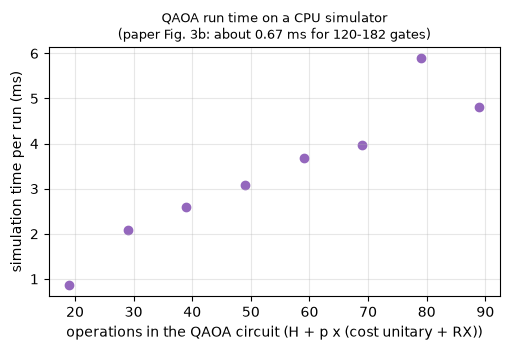

In [13]:
def gate_count(n, nf, layers):
    """Native gates after writing every Rot as RZ-RY-RZ: nf data rotations + layers x (3n single-qubit + n CNOT)."""
    return nf + layers * (3 * n + n)
rows = []
for g in GROUPS:
    n = NETS[g].n; Xg = data0["X"]["test"][:, GROUPS.index(g) * FEATS_PER_GROUP:(GROUPS.index(g) + 1) * FEATS_PER_GROUP]
    t0 = time.perf_counter(); NETS[g].predict(models0[g]["w"], Xg); dt = time.perf_counter() - t0
    rows.append(dict(layer=g, qubits=n, trainable_angles=NETS[g].n_params, gates=gate_count(n, FEATS_PER_GROUP, N_LAYERS), inference_us_per_flow=dt / len(Xg) * 1e6))
tot = pd.DataFrame(rows); display(tot.round(1))
print(f"whole detection layer: {tot.qubits.sum()} qubits, {tot.gates.sum()} gates, {tot.inference_us_per_flow.sum():.0f} microseconds per flow on this CPU simulator")

qaoa_rows = []
for p in range(1, 9):
    gam, bet = np.full(p, 0.8), np.full(p, 0.4)
    t0 = time.perf_counter()
    for _ in range(20): qaoa_probs(gam, bet, cn0)
    qaoa_rows.append(dict(depth_p=p, gates=N_QAOA + p * (1 + N_QAOA), ms_per_run=(time.perf_counter() - t0) / 20 * 1e3))
qr = pd.DataFrame(qaoa_rows)
fig, ax = plt.subplots(figsize=(5.2, 3.6)); ax.scatter(qr.gates, qr.ms_per_run, color="tab:purple")
ax.set_xlabel("operations in the QAOA circuit (H + p x (cost unitary + RX))"); ax.set_ylabel("simulation time per run (ms)")
ax.set_title("QAOA run time on a CPU simulator\n(paper Fig. 3b: about 0.67 ms for 120-182 gates)", fontsize=9); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## 10. Repeated runs with other seeds

Everything above is one run (seed 42). The whole pipeline, new random split, new weight initialisation, new batch order, new QAOA
restarts, is repeated for `N_RUNS` seeds so that the final table can show a mean and a standard deviation. The data sample itself
(which flows were drawn from the 2-million-flow file) stays the same. In `FAST_MODE` there is a single run.

In [14]:
all_filter, all_base = [res0.assign(run=0)], [base0.assign(run=0)]
qaoa_log = [dict(run=0, w=w_qaoa, brute=w_brute, cost_qaoa=cost0[q0["chosen"]], cost_brute=cost0.min(), cost_equal=cost0[np.argmax(W_ALL.sum(1))], rank=rank)]
for run in range(1, N_RUNS):
    s = SEED + run; t0 = time.perf_counter()
    d = prepare(s); mods = {g: train_subqnn(g, d, s, verbose=False) for g in GROUPS}; F = qnn_outputs(mods, d)
    ct = cost_table(F["val"], d["y"]["val"]); q = optimise_qaoa(phase_of(ct), s)
    wq, wb = W_ALL[q["chosen"]], W_ALL[int(np.argmin(ct))]
    r_, _ = run_filters(d, F, wq, wb); all_filter.append(r_.assign(run=run)); all_base.append(run_baselines(d).assign(run=run))
    qaoa_log.append(dict(run=run, w=wq, brute=wb, cost_qaoa=ct[q["chosen"]], cost_brute=ct.min(), cost_equal=ct[np.argmax(W_ALL.sum(1))], rank=int((ct < ct[q["chosen"]]).sum())))
    print(f"run {run} (seed {s}) done in {time.perf_counter()-t0:.0f} s | QAOA weights {np.round(wq, 2)} | test accuracy "
          f"{r_[(r_.variant == 'Quant-Jack (QAOA weights)') & (r_.split == 'test')].Accuracy.iloc[0]:.3f}")
filt_df, base_df = pd.concat(all_filter, ignore_index=True), pd.concat(all_base, ignore_index=True)
display(pd.DataFrame(qaoa_log)[["run", "w", "brute", "cost_qaoa", "cost_brute", "cost_equal", "rank"]])

run 1 (seed 43) done in 765 s | QAOA weights [0.14 0.   1.  ] | test accuracy 0.858


run 2 (seed 44) done in 661 s | QAOA weights [0.43 0.29 1.  ] | test accuracy 0.864


,run,w,brute,cost_qaoa,cost_brute,cost_equal,rank
0,0,"[0.14285714285714285, 0.42857142857142855, 1.0]","[0.14285714285714285, 0.5714285714285714, 1.0]",0.105952,0.104762,0.111905,1
1,1,"[0.14285714285714285, 0.0, 1.0]","[0.14285714285714285, 0.0, 0.5714285714285714]",0.122619,0.111905,0.133333,17
2,2,"[0.42857142857142855, 0.2857142857142857, 1.0]","[0.42857142857142855, 0.2857142857142857, 0.28...",0.125000,0.120238,0.126190,31


## 11. Summary over runs and the paper's figures redrawn

Mean +- standard deviation over the runs (one run in `FAST_MODE`, so the deviation then is 0 by construction).

Test split, mean +- std over 3 run(s):


,Accuracy,F1,Recall,Specificity,FER,FDR,MAPE
Eq. 15 (freq + traffic only),0.859 +- 0.014,0.862 +- 0.014,0.877 +- 0.035,0.842 +- 0.04,0.158 +- 0.04,0.151 +- 0.028,0.11 +- 0.015
Quant-Jack (QAOA weights),0.87 +- 0.013,0.867 +- 0.013,0.843 +- 0.031,0.897 +- 0.039,0.103 +- 0.039,0.106 +- 0.033,0.091 +- 0.015
brute-force best weights,0.87 +- 0.009,0.865 +- 0.012,0.833 +- 0.031,0.907 +- 0.021,0.093 +- 0.021,0.099 +- 0.018,0.088 +- 0.006
equal weights,0.874 +- 0.012,0.865 +- 0.016,0.811 +- 0.032,0.936 +- 0.008,0.064 +- 0.008,0.073 +- 0.006,0.079 +- 0.004
freq layer alone,0.821 +- 0.011,0.826 +- 0.016,0.855 +- 0.044,0.787 +- 0.023,0.213 +- 0.023,0.199 +- 0.01,0.143 +- 0.003
time layer alone,0.833 +- 0.004,0.826 +- 0.008,0.79 +- 0.027,0.876 +- 0.02,0.124 +- 0.02,0.135 +- 0.014,0.114 +- 0.003
traffic layer alone,0.852 +- 0.011,0.844 +- 0.006,0.803 +- 0.03,0.901 +- 0.051,0.099 +- 0.051,0.106 +- 0.05,0.099 +- 0.018
LogisticRegression,0.91 +- 0.003,0.907 +- 0.003,0.884 +- 0.007,0.935 +- 0.005,0.065 +- 0.005,0.068 +- 0.005,0.061 +- 0.002
RandomForest,0.985 +- 0.002,0.985 +- 0.002,0.98 +- 0.005,0.989 +- 0.003,0.011 +- 0.003,0.011 +- 0.003,0.01 +- 0.001
RandomForest on 'freq' features only,0.949 +- 0.004,0.949 +- 0.003,0.944 +- 0.005,0.955 +- 0.009,0.045 +- 0.009,0.045 +- 0.009,0.036 +- 0.004


Later (March 2022) set:


,Accuracy,F1,Recall,Specificity,FER,FDR,MAPE
Eq. 15 (freq + traffic only),0.838 +- 0.022,0.844 +- 0.019,0.872 +- 0.008,0.804 +- 0.039,0.196 +- 0.039,0.183 +- 0.031,0.13 +- 0.021
Quant-Jack (QAOA weights),0.854 +- 0.011,0.848 +- 0.009,0.819 +- 0.049,0.888 +- 0.061,0.112 +- 0.061,0.115 +- 0.05,0.101 +- 0.02
brute-force best weights,0.863 +- 0.018,0.854 +- 0.026,0.812 +- 0.062,0.914 +- 0.032,0.086 +- 0.032,0.093 +- 0.028,0.09 +- 0.007
equal weights,0.854 +- 0.026,0.837 +- 0.034,0.758 +- 0.059,0.95 +- 0.009,0.05 +- 0.009,0.061 +- 0.007,0.085 +- 0.011
freq layer alone,0.676 +- 0.111,0.586 +- 0.179,0.518 +- 0.248,0.834 +- 0.028,0.166 +- 0.028,0.263 +- 0.054,0.203 +- 0.049
time layer alone,0.692 +- 0.012,0.619 +- 0.032,0.505 +- 0.054,0.879 +- 0.034,0.121 +- 0.034,0.189 +- 0.03,0.184 +- 0.006
traffic layer alone,0.829 +- 0.019,0.825 +- 0.017,0.808 +- 0.041,0.849 +- 0.057,0.15 +- 0.057,0.153 +- 0.049,0.123 +- 0.022
LogisticRegression,0.9 +- 0.005,0.9 +- 0.005,0.898 +- 0.008,0.903 +- 0.002,0.097 +- 0.002,0.098 +- 0.002,0.074 +- 0.003
RandomForest,0.886 +- 0.038,0.871 +- 0.047,0.78 +- 0.076,0.993 +- 0.0,0.007 +- 0.0,0.009 +- 0.001,0.059 +- 0.019
RandomForest on 'freq' features only,0.706 +- 0.004,0.617 +- 0.007,0.472 +- 0.006,0.94 +- 0.002,0.06 +- 0.002,0.112 +- 0.005,0.162 +- 0.003


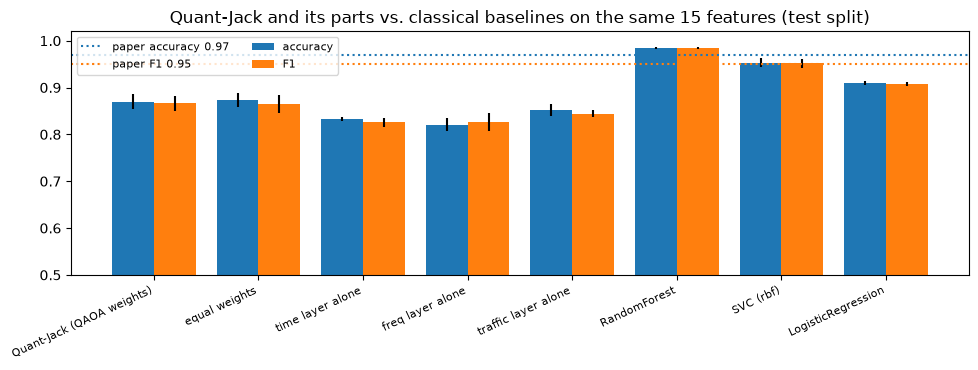

In [15]:
metrics = ["Accuracy", "F1", "Recall", "Specificity", "FER", "FDR", "MAPE"]
def summarize(df, split, key):
    g = df[df.split == split].groupby(key)[metrics]
    return (g.mean().round(3).astype(str) + " +- " + g.std(ddof=0).round(3).astype(str))
filt_test = summarize(filt_df, "test", "variant"); base_test = summarize(base_df, "test", "model")
print(f"Test split, mean +- std over {N_RUNS} run(s):"); display(pd.concat([filt_test, base_test]))
print("Later (March 2022) set:"); display(pd.concat([summarize(filt_df, "late", "variant"), summarize(base_df, "late", "model")]))

# Fig. 3-style bar chart of accuracy/F1 for the main contenders
mm = pd.concat([filt_df[filt_df.split == "test"].rename(columns={"variant": "model"}), base_df[base_df.split == "test"]])
order = ["Quant-Jack (QAOA weights)", "equal weights", "time layer alone", "freq layer alone", "traffic layer alone", "RandomForest", "SVC (rbf)", "LogisticRegression"]
agg = mm[mm.model.isin(order)].groupby("model")[["Accuracy", "F1"]].agg(["mean", "std"]).reindex(order)
fig, ax = plt.subplots(figsize=(10, 3.8)); x = np.arange(len(order))
ax.bar(x - 0.2, agg[("Accuracy", "mean")], 0.4, yerr=agg[("Accuracy", "std")].fillna(0), label="accuracy", color="tab:blue")
ax.bar(x + 0.2, agg[("F1", "mean")], 0.4, yerr=agg[("F1", "std")].fillna(0), label="F1", color="tab:orange")
ax.axhline(0.97, color="tab:blue", ls=":", label="paper accuracy 0.97"); ax.axhline(0.95, color="tab:orange", ls=":", label="paper F1 0.95")
ax.set_xticks(x); ax.set_xticklabels(order, rotation=25, ha="right", fontsize=8); ax.set_ylim(0.5, 1.02); ax.legend(fontsize=8, ncol=2)
ax.set_title("Quant-Jack and its parts vs. classical baselines on the same 15 features (test split)"); plt.tight_layout(); plt.show()

## 12. Paper versus this notebook

Each row is one claim of the paper. The verdict is **reproduced** when our value is within 0.02 of the paper's (the brief's
tolerance: 2 accuracy points, 0.02 for the other ratios), **not reached** when we are more than 0.02 worse, **exceeded** when
more than 0.02 better. For FER, MAPE and FDR smaller is better. Claims that need hardware or a network simulator the paper does
not describe are marked **cannot be checked**. All our numbers are on CESNET-MINER22 flows, **not** on the paper's private
IIoT mixture, so "reproduced" here would mean "the pipeline reaches the same level on a comparable detection task", and "exceeded" in
particular is not evidence against the paper.

In [16]:
PAPER = {"F1": 0.95, "Recall": 0.92, "Accuracy": 0.97, "FER": 0.05, "MAPE": 0.02, "Specificity": 0.95, "FDR": 0.03}
LOWER_IS_BETTER = {"FER", "MAPE", "FDR"}; TOL = 0.02
prop = filt_df[(filt_df.variant == "Quant-Jack (QAOA weights)") & (filt_df.split == "test")][metrics]
mu, sd = prop.mean(), prop.std(ddof=0)

def verdict(paper, ours, lower=False, tol=TOL):
    if abs(ours - paper) <= tol: return "reproduced"
    better = (ours < paper) if lower else (ours > paper)
    return "exceeded" if better else "not reached"

rows = [dict(claim=f"Table II: {m}", paper=PAPER[m], notebook=f"{mu[m]:.3f} +- {sd[m]:.3f}", verdict=verdict(PAPER[m], mu[m], m in LOWER_IS_BETTER)) for m in PAPER]
late = filt_df[(filt_df.variant == "Quant-Jack (QAOA weights)") & (filt_df.split == "late")][metrics].mean()
rows.append(dict(claim="Accuracy on the later (March 2022) flows", paper=0.97, notebook=f"{late['Accuracy']:.3f}", verdict=verdict(0.97, late["Accuracy"])))
rf = base_df[(base_df.model == "RandomForest") & (base_df.split == "test")].Accuracy.mean()
rows.append(dict(claim="Accuracy above QSVM+RBM [16] (0.92) and HQMM [15] (0.88), as published (different data)", paper="0.97 > 0.92",
                 notebook=f"{mu['Accuracy']:.3f}", verdict="reproduced (above 0.92)" if mu["Accuracy"] > 0.92 else "not reached (below 0.92)"))
rows.append(dict(claim="QNN scheme at least as good as a classical model on the same inputs (abstract: 'efficacy against classical designs')",
                 paper="qualitative", notebook=f"Quant-Jack {mu['Accuracy']:.3f} vs random forest {rf:.3f}",
                 verdict="reproduced" if mu["Accuracy"] >= rf - TOL else "not reached"))
ql = pd.DataFrame(qaoa_log);
rows.append(dict(claim="QAOA weights improve on un-optimised (equal) weights (validation cost of Eq. 16)", paper="qualitative", notebook=f"QAOA {ql.cost_qaoa.mean():.4f} vs equal {ql.cost_equal.mean():.4f} (best possible {ql.cost_brute.mean():.4f})",
                 verdict="reproduced" if ql.cost_qaoa.mean() < ql.cost_equal.mean() - 1e-9 else "not reached (no better than equal weights)"))
eq_test = filt_df[(filt_df.variant == "equal weights") & (filt_df.split == "test")].Accuracy.mean()
rows.append(dict(claim="QAOA weights beat equal weights on the held-out test split (accuracy)", paper="qualitative", notebook=f"QAOA {mu['Accuracy']:.3f} vs equal {eq_test:.3f}",
                 verdict="reproduced" if mu["Accuracy"] > eq_test + 0.005 else "not reached (no gain on unseen flows)"))
rows.append(dict(claim="Fig. 3c: throughput 11.84 Kbps vs 15 KBps at 60 nodes, 23.44 % average improvement", paper="11.84 / 15 / 23.44 %", notebook="not measured", verdict="cannot be checked"))
rows.append(dict(claim="Fig. 3b: QAOA run time about 0.67 ms for 120-182 gates", paper="0.67 ms", notebook=f"{qr.ms_per_run.iloc[2]:.2f} ms for {int(qr.gates.iloc[2])} operations on a CPU simulator", verdict="cannot be checked (simulator, not the paper's device)"))
rows.append(dict(claim="Fig. 3a: smooth convergence surface in (gamma, beta)", paper="qualitative figure", notebook="section 7: a smooth surface with one broad minimum", verdict="cannot be checked (qualitative figure, no numbers)"))
cmp_df = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 120); display(cmp_df)
print(f"\nNotebook: mean over {N_RUNS} run(s), data = CESNET-MINER22 sample of {2*N_PER_CLASS:,} flows, QNN training {EPOCHS} epochs ({OPTIMIZER}).")

,claim,paper,notebook,verdict
0,Table II: F1,0.95,0.867 +- 0.013,not reached
1,Table II: Recall,0.92,0.843 +- 0.031,not reached
2,Table II: Accuracy,0.97,0.870 +- 0.013,not reached
3,Table II: FER,0.05,0.103 +- 0.039,not reached
4,Table II: MAPE,0.02,0.091 +- 0.015,not reached
5,Table II: Specificity,0.95,0.897 +- 0.039,not reached
6,Table II: FDR,0.03,0.106 +- 0.033,not reached
7,Accuracy on the later (March 2022) flows,0.97,0.853,not reached
8,"Accuracy above QSVM+RBM [16] (0.92) and HQMM [15] (0.88), as published (different data)",0.97 > 0.92,0.870,not reached (below 0.92)
9,QNN scheme at least as good as a classical model on the same inputs (abstract: 'efficacy against classical designs'),qualitative,Quant-Jack 0.870 vs random forest 0.985,not reached



Notebook: mean over 3 run(s), data = CESNET-MINER22 sample of 6,000 flows, QNN training 50 epochs (adam).


## Reading the paper critically

**The data is not the paper's data, and probably could not carry the paper's claim.** CSE-CIC-IDS2018 has no cryptojacking
class, and the "live IIoT data" is neither described nor released, so nobody can say which flows were labelled malicious or how
the 15 features were chosen. Everything above uses ISP flows of cryptominers and ordinary traffic. Even there the task is not a
mining-malware-in-IIoT task: the flows are miner-to-pool connections seen at a national network edge. A model that does well on
this file is evidence about this file only.

**Table II cannot be internally consistent.** With miners as the positive class, accuracy is a weighted mean of recall and
specificity, so it must lie between them. The paper reports recall 0.92, specificity 0.95 and accuracy 0.97, which is outside
that interval whatever the class balance. F1 = 0.95 together with recall = 0.92 implies precision of about 0.98, i.e. an FDR of about
0.02, not the reported 0.03. MAPE (mean absolute *percentage* error) has no meaning for a binary label, and "FER" is
not defined in the text (we used the false-positive rate, which reproduces `1 - specificity = 0.05`). The code in section 12 uses
these definitions; the numbers in the paper's table cannot all be matched by any single classifier.

**The comparison methods are not comparable.** HQMM [15] is a hidden-Markov model with a quantum receiver for identifying
footsteps in a 2-D image field; QSVM+RBM [16] is a quantum-annealing restricted Boltzmann machine trained on another cybersecurity
data set. Both numbers in Table II are cited values, not re-runs on the paper's hybrid data, and no classical classifier
(random forest, SVM, logistic regression) is trained at all, although the abstract says the scheme shows "efficacy against classical
security designs". Section 4 shows what such baselines reach on the substitute data.

**QAOA is not needed for what it does here.** The weights `w_time, w_freq, w_traffic` are three numbers. A grid of 8 levels per
weight has 512 candidates that a laptop scores exhaustively in a second, and a logistic regression on `F_time, F_freq, F_traffic`
would fit them directly. The QAOA circuit has to be told the answer's cost table (the diagonal of the cost Hamiltonian is the
512-entry table the brute force computes), so any speed-up claim is moot at this size. The paper does not specify the
cost Hamiltonian at all, and the two uses of `gamma` and `beta` (QAOA angles in Algorithm 1, filter weights in Eq. 15) and of
`lambda` (decay constant in Eq. 7, error weight in Eq. 16) collide. In our runs QAOA does what it is built to do on the
validation cost (mean 0.118 against 0.124 for equal weights and 0.112 for the true best of the 512 triples; the optimised distribution
has a lower expected cost than a random triple, 0.114 against 0.125 in run 0, but in that run it puts only 0.7 % of its probability on the best
triple, and the most-measured bit string was the best triple in none of the three runs: 1, 17 and 31 triples out of 512 were better). The gain does not carry over: on the held-out test split
the QAOA weights (accuracy 0.870 +- 0.013) are no better than equal weights (0.874 +- 0.012). A weighted sum of three
layers does help, a little: the best single layer reaches 0.852, the sum 0.87.

**The throughput claim is hard to read.** Fig. 3c is described as "15 KBps" for the classical baseline against "11.84 Kbps" for the
proposed scheme at 60 nodes and then called an improvement; the units differ (bytes vs bits per second), a lower throughput would
be worse unless the figure shows a cost, and `(15 - 11.84) / 15 = 21.1 %`, not the 23.44 % quoted (which is said to be an average over
100 nodes). No network simulator, traffic model or definition of "throughput utilisation" is given. The 0.67 ms QAOA run time cannot
come from a 20-qubit quantum processor with real gate times, and the 15 features cannot fill 20 qubits without a design that the
paper does not describe.

**Temporal drift is bigger than the differences between the quantum variants.** The March 2022 flows come from the same
network a few weeks after the training flows, yet the random forest drops from 0.985 to 0.886 accuracy (its recall falls from 0.98 to 0.78),
the time layer alone from 0.833 to 0.692 and the freq layer alone from 0.821 to 0.676, while logistic regression (0.91 to 0.90) and the full
Quant-Jack sum (0.870 to 0.854) lose a point or two. A random 70/30 split, the paper's protocol, never shows this, and it means that
"0.97 accuracy" on a random split says little about a deployed detector.

**Conclusion.** The pipeline can be implemented as described and it runs, but the paper's headline numbers are not reached:
on public cryptominer flows the QNN + QAOA + threshold scheme gets about 0.87 accuracy (F1 0.87, recall 0.84, specificity 0.90),
below the paper's 0.97 / 0.95 / 0.92 / 0.95, and below a plain logistic regression (0.91) and a random forest (0.985) on the same 15
features. Section 12 lists each claim; the throughput and run-time claims cannot be tested at all.

## Exercises

1. **Ports are a shortcut.** Add one more feature, `DST_PORT in {3333, 4444, 5555, 14444, 14433}`, to the traffic group (read the
   `uint16 DST_PORT` column in `RAW_COLS`) and re-run. How far do the classical baselines and the QNN move? What does that say about
   a data set where the label can be read from one header field?
2. **Plain gradient descent.** Set `OPTIMIZER = "gd"` (the paper's choice) and compare the learning curves of section 6 with
   Adam at the same learning rate 0.01. How many epochs does gradient descent need to reach the same validation accuracy?
3. **QAOA depth and bits.** Vary `QAOA_LAYERS` (1 to 4) and `BITS_PER_WEIGHT` (2 to 4). Plot the probability that QAOA assigns to the
   best weight triple against depth, and compare with brute force. For which depth is QAOA no worse than random guessing?
4. **One 20-qubit circuit.** Replace the three separate layers by a single `SubQNN(20, 15, N_LAYERS)` that sees all 15 features
   (the statevector has 2^20 amplitudes, so reduce the batch size or the number of epochs). Is the joint circuit better than the
   weighted sum of three small ones? Which design makes the paper's "weighted sum" unnecessary?
5. **Finite shots.** The QNN outputs here are exact expectation values. Replace `F` by a sample mean of 1,024 measurement shots
   (draw each qubit-0 outcome with probability `(1 + F) / 2`), recompute the cost table, the threshold `T` and the metrics. How much
   does the shot noise move `T` and the accuracy, and how many shots does the filter need to match the exact numbers?